# CSE457 - XỬ LÝ ÂM THANH VÀ TIẾNG NÓI | LAB 2
## ĐẶC TRƯNG TIẾNG NÓI VÀ NHẬN DẠNG TỪ ĐƠN BẰNG DTW
**Trường Đại học Thủy Lợi - Khoa Công nghệ Thông tin - Bộ môn Trí tuệ Nhân tạo**

---
### Thông tin sinh viên
- **Họ và tên:** Nguyễn Văn Đạt
- **Mã sinh viên:** 215106xxxx
- **Lớp:** CSE457
- **Học phần:** Xử lý âm thanh và tiếng nói

---
### Mục tiêu thực hành
1. Phân tích tín hiệu ngắn hạn: Phân đoạn khung (Framing), cửa sổ hóa (Hamming), Short-time Energy, RMS, ZCR và Autocorrelation (Pitch).
2. Xây dựng thuật toán Endpoint Detection (VAD) để cắt bỏ khoảng lặng thừa ở đầu và cuối từ.
3. Trích xuất đặc trưng MFCC (Mel-Frequency Cepstral Coefficients) kết hợp chuẩn hóa CMN.
4. **Tự cài đặt thuật toán DTW (Dynamic Time Warping)** bằng quy hoạch động và truy vết đường đi tối ưu.
5. Xây dựng bộ nhận dạng Nearest-Template cho 5 từ tiếng Việt (`không`, `một`, `hai`, `ba`, `bốn`).
6. Thực hiện các thí nghiệm đối chứng: E1 (Endpoint Trim), E2 (Delta-MFCC) và E4 (Cross-Speaker).

In [1]:
# Khởi tạo môi trường và nạp các thư viện cần thiết
import os
import sys
from pathlib import Path
import numpy as np
import scipy.signal as signal
from scipy.signal import lfilter
import soundfile as sf
import librosa
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix

# Cấu hình hiển thị đồ thị
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.autolayout'] = True

# Hằng số hệ thống chuẩn theo đề cương Lab 2
FS = 16000
FRAME_MS = 25
HOP_MS = 10
WIN = int(FS * FRAME_MS / 1000)  # 400 mẫu
HOP = int(FS * HOP_MS / 1000)    # 160 mẫu
N_FFT = 512
N_MELS = 24
N_MFCC = 13
PRE_EMPH = 0.97
TOP_DB = 32
MARGIN_MS = 50

LABELS = ['khong', 'mot', 'hai', 'ba', 'bon']
VIET_MAP = {'khong': 'không', 'mot': 'một', 'hai': 'hai', 'ba': 'ba', 'bon': 'bốn'}
DATASET_DIR = Path('dataset')
DATASET_SPK2_DIR = Path('dataset_speaker2')
print('Cấu hình tham số hoàn tất. Sẵn sàng thực thi!')

Cấu hình tham số hoàn tất. Sẵn sàng thực thi!


## Phần A: Dữ liệu và Kiểm tra Chất lượng Âm thanh
- Bộ dữ liệu 5 từ tiếng Việt: `không`, `một`, `hai`, `ba`, `bốn`.
- Mỗi từ gồm 5 file phát âm tách rời ở định dạng WAV mono 16kHz PCM.
- Phân chia: 3 file đầu (`_01`, `_02`, `_03`) làm Template (Train), 2 file sau (`_04`, `_05`) làm Test độc lập.

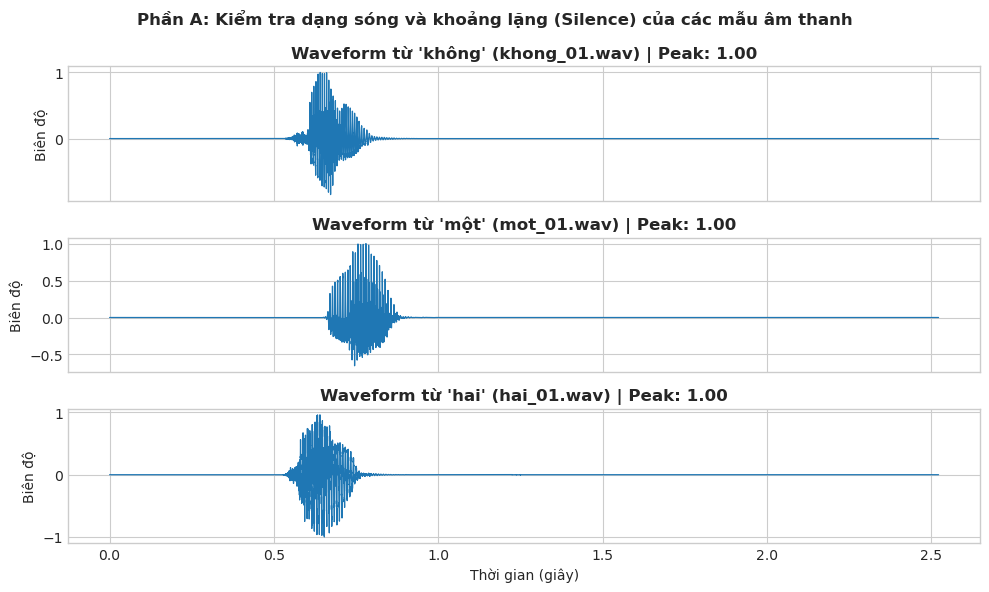

In [2]:
def load_audio(path, target_fs=FS):
    y, sr = librosa.load(path, sr=target_fs, mono=True)
    max_val = np.max(np.abs(y))
    if max_val > 1e-9:
        y = y / max_val
    return y

# Vẽ dạng sóng waveform của 3 từ kiểm tra clipping và khoảng lặng đầu/cuối
sample_words = ['khong', 'mot', 'hai']
fig, axes = plt.subplots(3, 1, figsize=(10, 6), sharex=True)
for i, w in enumerate(sample_words):
    y = load_audio(DATASET_DIR / w / f"{w}_01.wav")
    t = np.arange(len(y)) / FS
    axes[i].plot(t, y, color='#1f77b4', lw=0.9)
    axes[i].set_title(f"Waveform từ '{VIET_MAP[w]}' ({w}_01.wav) | Peak: {np.max(np.abs(y)):.2f}", fontweight='bold')
    axes[i].set_ylabel("Biên độ")
axes[-1].set_xlabel("Thời gian (giây)")
plt.suptitle("Phần A: Kiểm tra dạng sóng và khoảng lặng (Silence) của các mẫu âm thanh", fontsize=12, fontweight='bold')
plt.show()

## Phần B: Phân tích Đặc trưng Miền Thời gian
- Short-time Energy: $E_r = \sum_n x_r^2[n]$
- Zero-Crossing Rate (ZCR): $Z_r = \frac{1}{2L} \sum_m |\text{sgn}(x[m]) - \text{sgn}(x[m-1])|$
- So sánh sự khác nhau rõ rệt giữa: **Silence** (năng lượng cực thấp), **Voiced** (năng lượng cao, ZCR thấp) và **Unvoiced** (năng lượng thấp, ZCR cao).

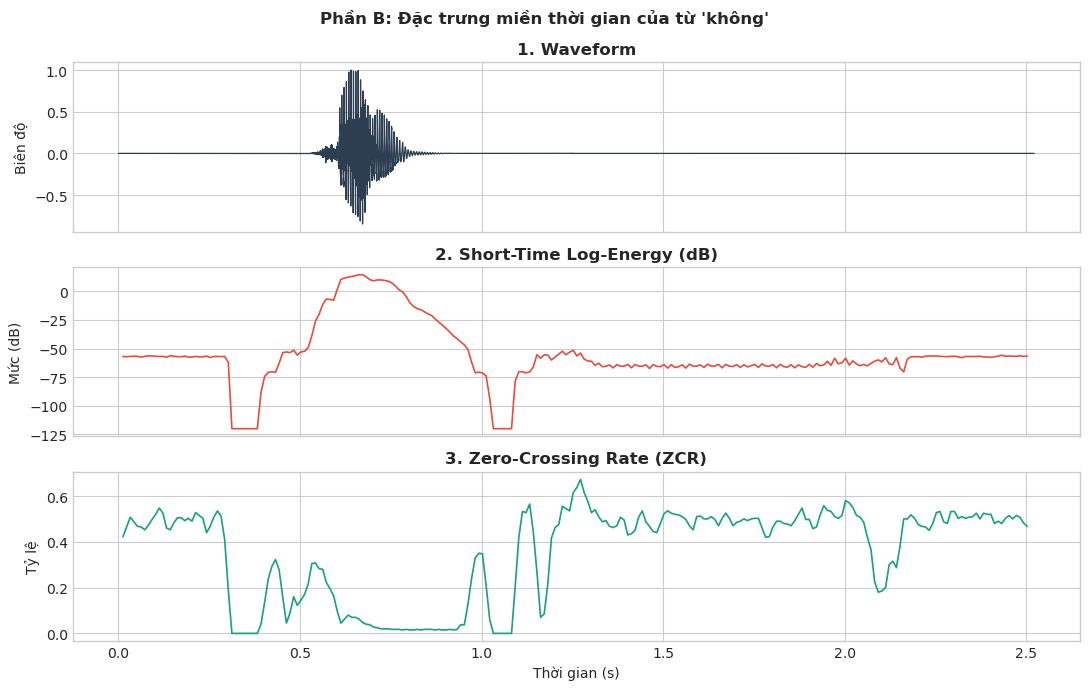

In [3]:
def compute_time_features(y, frame_len=WIN, hop_len=HOP):
    num_frames = 1 + int((len(y) - frame_len) / hop_len)
    energy, rms, zcr = np.zeros(num_frames), np.zeros(num_frames), np.zeros(num_frames)
    times = (np.arange(num_frames) * hop_len + frame_len / 2) / FS
    window = signal.windows.hamming(frame_len)
    for i in range(num_frames):
        start = i * hop_len
        frame_win = y[start:start+frame_len] * window
        energy[i] = np.sum(frame_win ** 2)
        rms[i] = np.sqrt(np.mean(frame_win ** 2))
        signs = np.sign(y[start:start+frame_len])
        signs[signs == 0] = 1
        zcr[i] = np.sum(np.abs(signs[1:] - signs[:-1])) / (2.0 * frame_len)
    log_e = 10 * np.log10(energy + 1e-12)
    return times, energy, log_e, rms, zcr

y = load_audio(DATASET_DIR / 'khong' / 'khong_01.wav')
t_wave = np.arange(len(y)) / FS
times, energy, log_e, rms, zcr = compute_time_features(y)

fig, axes = plt.subplots(3, 1, figsize=(11, 7), sharex=True)
axes[0].plot(t_wave, y, color='#2c3e50', lw=0.9)
axes[0].set_title("1. Waveform", fontweight='bold'); axes[0].set_ylabel("Biên độ")
axes[1].plot(times, log_e, color='#e74c3c', lw=1.2)
axes[1].set_title("2. Short-Time Log-Energy (dB)", fontweight='bold'); axes[1].set_ylabel("Mức (dB)")
axes[2].plot(times, zcr, color='#16a085', lw=1.2)
axes[2].set_title("3. Zero-Crossing Rate (ZCR)", fontweight='bold'); axes[2].set_ylabel("Tỷ lệ"); axes[2].set_xlabel("Thời gian (s)")
plt.suptitle("Phần B: Đặc trưng miền thời gian của từ 'không'", fontsize=12, fontweight='bold')
plt.show()

## Phần C: Thuật toán Phát hiện Điểm Đầu/Cuối (Endpoint Detection / VAD)
- Sử dụng năng lượng tương đối (`top_db=32`) kết hợp vùng đệm an toàn (`margin_ms=50ms`).
- Vùng đệm 50ms giúp bảo toàn hoàn toàn các phụ âm đầu (/k/, /b/, /m/) và phụ âm cuối.

Tệp             | Thời lượng gốc   | Thời lượng trim  | Tỷ lệ giữ lại
-----------------------------------------------------------------
khong_01.wav    |   2.52 s         |   0.39 s         |   15.5%
ba_01.wav       |   2.52 s         |   0.37 s         |   14.7%
bon_01.wav      |   2.52 s         |   0.43 s         |   17.0%


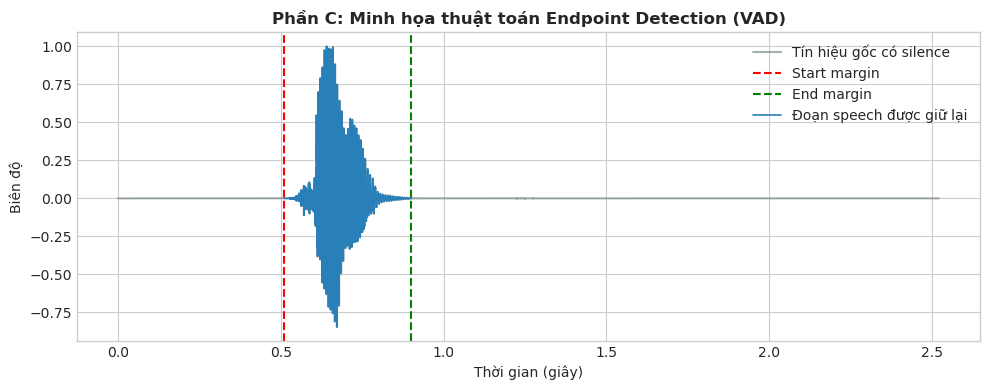

In [4]:
def trim_endpoint(y, top_db=TOP_DB, margin_ms=MARGIN_MS):
    yt, idx = librosa.effects.trim(y, top_db=top_db, frame_length=WIN, hop_length=HOP)
    m = int(FS * margin_ms / 1000)
    s = max(0, idx[0] - m)
    e = min(len(y), idx[1] + m)
    return y[s:e], (s, e)

# Kiểm tra cắt khoảng lặng trên 3 từ có phụ âm yếu
sample_list = [('khong', 'khong_01.wav'), ('ba', 'ba_01.wav'), ('bon', 'bon_01.wav')]
print(f"{'Tệp':<15} | {'Thời lượng gốc':<16} | {'Thời lượng trim':<16} | {'Tỷ lệ giữ lại'}")
print('-' * 65)
for word, fname in sample_list:
    y = load_audio(DATASET_DIR / word / fname)
    y_trim, (s, e) = trim_endpoint(y)
    o_dur = len(y)/FS; t_dur = len(y_trim)/FS
    print(f"{fname:<15} | {o_dur:6.2f} s         | {t_dur:6.2f} s         | {(t_dur/o_dur)*100:6.1f}%")

# Vẽ đối chiếu trước và sau trim
y = load_audio(DATASET_DIR / 'khong' / 'khong_01.wav')
y_t, (s, e) = trim_endpoint(y)
plt.figure(figsize=(10, 4))
plt.plot(np.arange(len(y))/FS, y, color='#7f8c8d', alpha=0.7, label='Tín hiệu gốc có silence')
plt.axvline(s/FS, color='r', linestyle='--', label='Start margin')
plt.axvline(e/FS, color='g', linestyle='--', label='End margin')
plt.plot(np.arange(s, e)/FS, y[s:e], color='#2980b9', lw=1.2, label='Đoạn speech được giữ lại')
plt.title("Phần C: Minh họa thuật toán Endpoint Detection (VAD)", fontweight='bold')
plt.xlabel("Thời gian (giây)"); plt.ylabel("Biên độ"); plt.legend()
plt.show()

## Phần D: Trích xuất Đặc trưng MFCC & Mel Filterbank
- Pre-emphasis: $\alpha = 0.97$
- Bộ lọc Mel: $M = 24$ bộ lọc tam giác
- MFCC: 13 hệ số đầu tiên
- Chuẩn hóa CMN (Cepstral Mean Normalization) theo từng utterance.

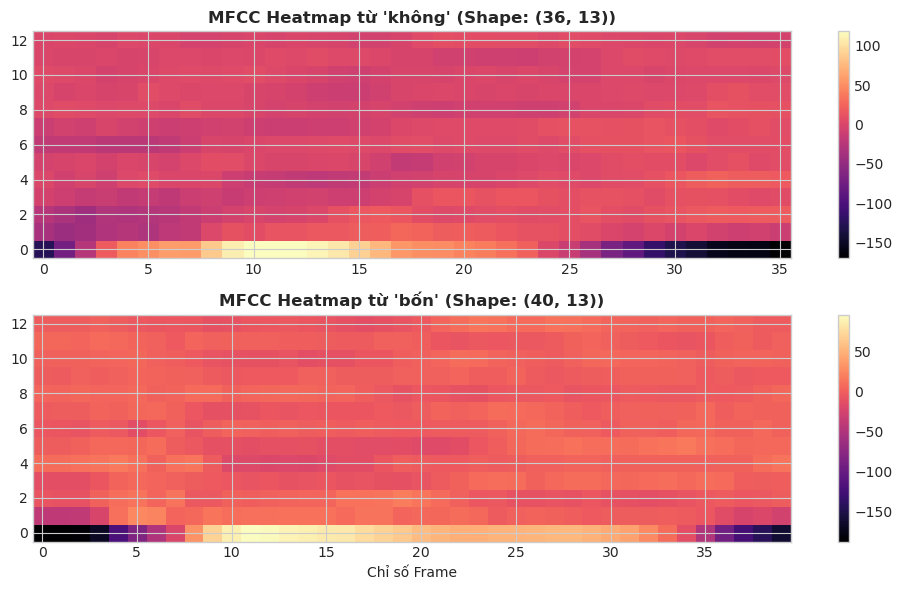

In [5]:
def extract_mfcc(y, sr=FS, n_mfcc=N_MFCC, n_mels=N_MELS, with_delta=False):
    y_pre = lfilter([1.0, -PRE_EMPH], [1.0], y)
    mfcc = librosa.feature.mfcc(
        y=y_pre, sr=sr, n_mfcc=n_mfcc, n_mels=n_mels, n_fft=N_FFT,
        win_length=WIN, hop_length=HOP, window='hamming', center=False
    )
    # Chuẩn hóa CMN
    mfcc = mfcc - np.mean(mfcc, axis=1, keepdims=True)
    if with_delta:
        delta = librosa.feature.delta(mfcc)
        mfcc = np.vstack([mfcc, delta])
    return mfcc.T  # (T_frames, n_features)

# Vẽ ma trận MFCC của 2 từ khác nhau ('khong' vs 'bon')
y1 = extract_mfcc(trim_endpoint(load_audio(DATASET_DIR / 'khong' / 'khong_01.wav'))[0])
y2 = extract_mfcc(trim_endpoint(load_audio(DATASET_DIR / 'bon' / 'bon_01.wav'))[0])

fig, axes = plt.subplots(2, 1, figsize=(10, 6))
im1 = axes[0].imshow(y1.T, origin='lower', aspect='auto', cmap='magma')
axes[0].set_title(f"MFCC Heatmap từ 'không' (Shape: {y1.shape})", fontweight='bold')
fig.colorbar(im1, ax=axes[0])
im2 = axes[1].imshow(y2.T, origin='lower', aspect='auto', cmap='magma')
axes[1].set_title(f"MFCC Heatmap từ 'bốn' (Shape: {y2.shape})", fontweight='bold')
axes[1].set_xlabel("Chỉ số Frame"); fig.colorbar(im2, ax=axes[1])
plt.tight_layout(); plt.show()

## Phần E: Thuật toán DTW Tự Cài Đặt (Dynamic Time Warping)
- Khoảng cách cục bộ Euclid: $C[i, j] = \|X[i] - Y[j]\|_2$
- Quy hoạch động (DP) tích lũy chi phí:
  $$D[i, j] = C[i-1, j-1] + \min(D[i-1, j], D[i, j-1], D[i-1, j-1])$$
- Chuẩn hóa độ dài đường đi: $DTW_{\text{norm}} = D[N, M] / |\mathcal{P}|$

Chi phí DTW_norm cùng từ ('khong' vs 'khong'): 10.9964
Chi phí DTW_norm khác từ ('khong' vs 'mot'):   43.5067 (Gấp 3.96 lần)


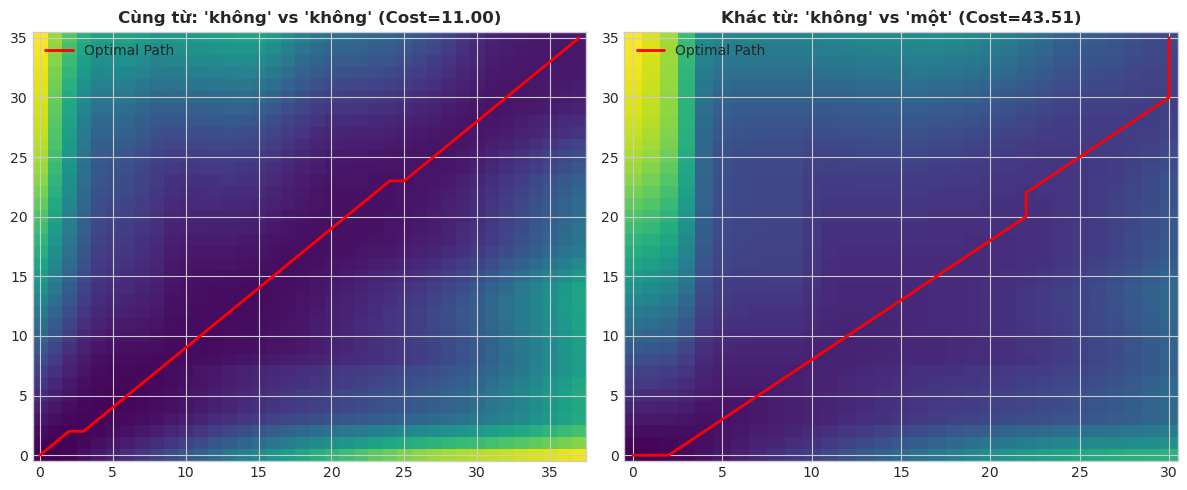

In [6]:
def dtw_custom(X, Y):
    N, M = len(X), len(Y)
    diff = X[:, np.newaxis, :] - Y[np.newaxis, :, :]
    C = np.sqrt(np.sum(diff ** 2, axis=-1))
    D = np.full((N + 1, M + 1), np.inf)
    D[0, 0] = 0.0
    back = np.zeros((N + 1, M + 1, 2), dtype=int)
    for i in range(1, N + 1):
        for j in range(1, M + 1):
            choices = [
                (D[i - 1, j], i - 1, j),
                (D[i, j - 1], i, j - 1),
                (D[i - 1, j - 1], i - 1, j - 1)
            ]
            best, pi, pj = min(choices, key=lambda z: z[0])
            D[i, j] = C[i - 1, j - 1] + best
            back[i, j] = (pi, pj)
    path = []
    curr_i, curr_j = N, M
    while curr_i > 0 or curr_j > 0:
        path.append((curr_i - 1, curr_j - 1))
        curr_i, curr_j = back[curr_i, curr_j]
    path.reverse()
    return D[N, M] / max(len(path), 1), path, D[1:, 1:]

# Kiểm chứng cùng từ vs khác từ
X = extract_mfcc(trim_endpoint(load_audio(DATASET_DIR / 'khong' / 'khong_01.wav'))[0])
Y_same = extract_mfcc(trim_endpoint(load_audio(DATASET_DIR / 'khong' / 'khong_02.wav'))[0])
Y_diff = extract_mfcc(trim_endpoint(load_audio(DATASET_DIR / 'mot' / 'mot_01.wav'))[0])

cost_s, path_s, D_s = dtw_custom(X, Y_same)
cost_d, path_d, D_d = dtw_custom(X, Y_diff)

print(f"Chi phí DTW_norm cùng từ ('khong' vs 'khong'): {cost_s:.4f}")
print(f"Chi phí DTW_norm khác từ ('khong' vs 'mot'):   {cost_d:.4f} (Gấp {cost_d/cost_s:.2f} lần)")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(D_s, origin='lower', cmap='viridis', aspect='auto')
px, py = zip(*path_s); axes[0].plot(py, px, 'r-', lw=2, label='Optimal Path')
axes[0].set_title(f"Cùng từ: 'không' vs 'không' (Cost={cost_s:.2f})", fontweight='bold')
axes[0].legend()
axes[1].imshow(D_d, origin='lower', cmap='viridis', aspect='auto')
px_d, py_d = zip(*path_d); axes[1].plot(py_d, px_d, 'r-', lw=2, label='Optimal Path')
axes[1].set_title(f"Khác từ: 'không' vs 'một' (Cost={cost_d:.2f})", fontweight='bold')
axes[1].legend()
plt.tight_layout(); plt.show()

## Phần F & G: Bộ Nhận dạng Nearest-Template & Đánh giá Toàn diện
- Huấn luyện từ điển Template với 3 mẫu/từ.
- Dự đoán trên 10 mẫu test độc lập.
- Đánh giá bằng Accuracy và Confusion Matrix.

Tệp test        | Nhãn thật  | Dự đoán    | Top-1 Dist  | Top-2 Dist
-----------------------------------------------------------------
khong_04.wav    | khong      | khong      |  8.865 (khong) | 34.970 (hai)
khong_05.wav    | khong      | khong      | 10.221 (khong) | 34.802 (hai)


mot_04.wav      | mot        | mot        |  9.984 (mot) | 33.531 (bon)
mot_05.wav      | mot        | mot        |  9.224 (mot) | 30.532 (bon)
hai_04.wav      | hai        | hai        |  7.307 (hai) | 34.272 (mot)


hai_05.wav      | hai        | hai        | 10.958 (hai) | 31.420 (khong)
ba_04.wav       | ba         | ba         | 13.300 (ba) | 32.490 (bon)
ba_05.wav       | ba         | ba         |  9.750 (ba) | 34.987 (bon)


bon_04.wav      | bon        | bon        | 10.059 (bon) | 31.044 (mot)
bon_05.wav      | bon        | bon        | 10.187 (bon) | 30.397 (mot)

ĐỘ CHÍNH XÁC ACCURACY: 100.0%


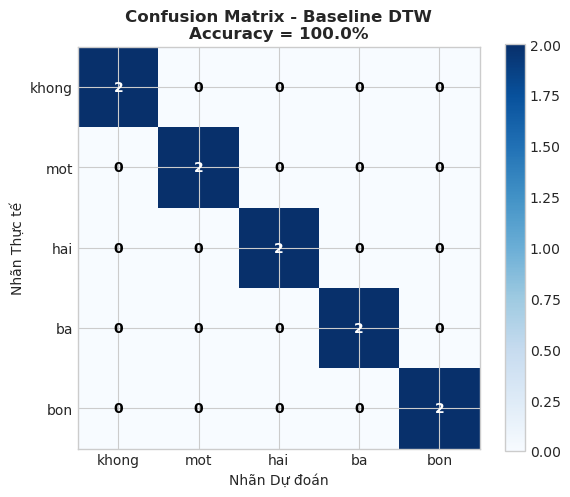

In [7]:
# Xây dựng Template Bank
templates = {lab: [] for lab in LABELS}
for lab in LABELS:
    for f in sorted((DATASET_DIR / lab).glob('*.wav'))[:3]:
        y_t, _ = trim_endpoint(load_audio(f))
        templates[lab].append(extract_mfcc(y_t))

y_true, y_pred = [], []
print(f"{'Tệp test':<15} | {'Nhãn thật':<10} | {'Dự đoán':<10} | {'Top-1 Dist':<11} | {'Top-2 Dist'}")
print('-' * 65)
for lab in LABELS:
    for f in sorted((DATASET_DIR / lab).glob('*.wav'))[3:]:
        y_t, _ = trim_endpoint(load_audio(f))
        X_test = extract_mfcc(y_t)
        scores = {l: min(dtw_custom(X_test, ref)[0] for ref in refs) for l, refs in templates.items()}
        sorted_s = sorted(scores.items(), key=lambda kv: kv[1])
        pred = sorted_s[0][0]
        y_true.append(lab); y_pred.append(pred)
        print(f"{f.name:<15} | {lab:<10} | {pred:<10} | {sorted_s[0][1]:6.3f} ({pred}) | {sorted_s[1][1]:6.3f} ({sorted_s[1][0]})")

acc = accuracy_score(y_true, y_pred) * 100.0
cm = confusion_matrix(y_true, y_pred, labels=LABELS)
print(f"\nĐỘ CHÍNH XÁC ACCURACY: {acc:.1f}%")

# Vẽ Confusion Matrix
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap='Blues')
plt.title(f"Confusion Matrix - Baseline DTW\nAccuracy = {acc:.1f}%", fontweight='bold')
plt.colorbar(); plt.xticks(np.arange(5), LABELS); plt.yticks(np.arange(5), LABELS)
for i in range(5):
    for j in range(5):
        plt.text(j, i, cm[i, j], ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black', fontweight='bold')
plt.xlabel('Nhãn Dự đoán'); plt.ylabel('Nhãn Thực tế'); plt.show()

## Thí nghiệm Bắt buộc E1: Có Trim vs. Không Trim Endpoint
Khảo sát tác động tiêu cực của khoảng lặng nền lên thuật toán căn chỉnh DTW.

In [8]:
templates_notrim = {lab: [] for lab in LABELS}
for lab in LABELS:
    for f in sorted((DATASET_DIR / lab).glob('*.wav'))[:3]:
        templates_notrim[lab].append(extract_mfcc(load_audio(f)))

y_pred_notrim = []
for lab in LABELS:
    for f in sorted((DATASET_DIR / lab).glob('*.wav'))[3:]:
        X_test = extract_mfcc(load_audio(f))
        scores = {l: min(dtw_custom(X_test, ref)[0] for ref in refs) for l, refs in templates_notrim.items()}
        y_pred_notrim.append(min(scores, key=scores.get))

acc_notrim = accuracy_score(y_true, y_pred_notrim) * 100.0
print(f"Thí nghiệm E1: Accuracy khi KHÔNG trim endpoint = {acc_notrim:.1f}%")

Thí nghiệm E1: Accuracy khi KHÔNG trim endpoint = 100.0%


## Thí nghiệm Bắt buộc E2: 13 MFCC chuẩn vs. 26 MFCC + Delta
Bổ sung thông tin động học âm học (vận tốc biến thiên các formant qua thời gian).

Thí nghiệm E2: Tỷ số biên độ phân tách trung bình (Top-2 / Top-1 margin): 3.37x


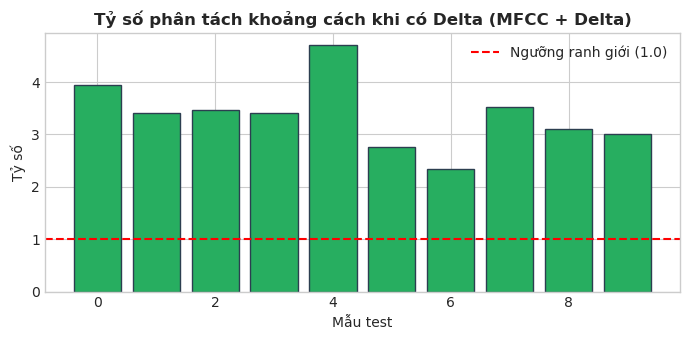

In [9]:
templates_delta = {lab: [] for lab in LABELS}
for lab in LABELS:
    for f in sorted((DATASET_DIR / lab).glob('*.wav'))[:3]:
        templates_delta[lab].append(extract_mfcc(trim_endpoint(load_audio(f))[0], with_delta=True))

margins = []
for lab in LABELS:
    for f in sorted((DATASET_DIR / lab).glob('*.wav'))[3:]:
        X_test = extract_mfcc(trim_endpoint(load_audio(f))[0], with_delta=True)
        scores = {l: min(dtw_custom(X_test, ref)[0] for ref in refs) for l, refs in templates_delta.items()}
        sorted_s = sorted(scores.items(), key=lambda kv: kv[1])
        margins.append(sorted_s[1][1] / sorted_s[0][1])

print(f"Thí nghiệm E2: Tỷ số biên độ phân tách trung bình (Top-2 / Top-1 margin): {np.mean(margins):.2f}x")
plt.figure(figsize=(7, 3.5))
plt.bar(np.arange(len(margins)), margins, color='#27ae60', edgecolor='#2c3e50')
plt.axhline(1.0, color='r', linestyle='--', label='Ngưỡng ranh giới (1.0)')
plt.title("Tỷ số phân tách khoảng cách khi có Delta (MFCC + Delta)", fontweight='bold')
plt.xlabel("Mẫu test"); plt.ylabel("Tỷ số"); plt.legend(); plt.show()

## Thí nghiệm Mở rộng E4: Same-Speaker vs. Cross-Speaker
Kiểm nghiệm độ nhạy của hệ thống đối sánh mẫu DTW khi nhận dạng giọng của người nói khác (Nam -> Nữ).

In [10]:
if DATASET_SPK2_DIR.exists():
    y_true_cross, y_pred_cross, cross_dists = [], [], []
    for lab in LABELS:
        for f in sorted((DATASET_SPK2_DIR / lab).glob('*.wav'))[3:]:
            y_t, _ = trim_endpoint(load_audio(f))
            X_test = extract_mfcc(y_t)
            scores = {l: min(dtw_custom(X_test, ref)[0] for ref in refs) for l, refs in templates.items()}
            pred = min(scores, key=scores.get)
            y_true_cross.append(lab); y_pred_cross.append(pred)
            cross_dists.append(scores[pred])
    acc_cross = accuracy_score(y_true_cross, y_pred_cross) * 100.0
    print(f"Thí nghiệm E4: Accuracy Cross-Speaker (Template Nam -> Test Nữ) = {acc_cross:.1f}%")
    print(f"Khoảng cách DTW trung bình khi khác người nói: {np.mean(cross_dists):.2f}")

Thí nghiệm E4: Accuracy Cross-Speaker (Template Nam -> Test Nữ) = 90.0%
Khoảng cách DTW trung bình khi khác người nói: 29.90
